In [50]:

# STEP 1: Import Required Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px
import plotly.graph_objects as go

import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Visualization settings
sns.set_style("whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [51]:

# STEP 2: Load Dataset

import pandas as pd

file_path = "../data/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(file_path)

print("=" * 60)
print("CUSTOMER CHURN DATASET")
print("=" * 60)

print("Dataset loaded successfully!")
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nFirst 5 Records:")
display(df.head())


CUSTOMER CHURN DATASET
Dataset loaded successfully!
Number of Rows: 7043
Number of Columns: 21

First 5 Records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [52]:

# STEP 3: Dataset Information

print("Dataset Information:")
df.info()

print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

In [53]:

# STEP 4: Data Quality Assessment

print("=" * 60)
print("DATA QUALITY REPORT")
print("=" * 60)

# 1. Missing Values
print("\n1. Missing Values:")
print(df.isnull().sum())

# 2. Total Missing Values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# 3. Duplicate Records
print("\n2. Duplicate Records:", df.duplicated().sum())

# 4. Data Types
print("\n3. Column Data Types:")
print(df.dtypes)

# 5. Dataset Statistics
print("\n4. Numerical Summary:")
display(df.describe())


DATA QUALITY REPORT

1. Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total Missing Values: 0

2. Duplicate Records: 0

3. Column Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies     

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [54]:

# STEP 5: Check Unique Values

print("UNIQUE VALUE ANALYSIS")
print("=" * 60)

for column in df.columns:
    print(f"{column}: {df[column].nunique()} unique values")


UNIQUE VALUE ANALYSIS
customerID: 7043 unique values
gender: 2 unique values
SeniorCitizen: 2 unique values
Partner: 2 unique values
Dependents: 2 unique values
tenure: 73 unique values
PhoneService: 2 unique values
MultipleLines: 3 unique values
InternetService: 3 unique values
OnlineSecurity: 3 unique values
OnlineBackup: 3 unique values
DeviceProtection: 3 unique values
TechSupport: 3 unique values
StreamingTV: 3 unique values
StreamingMovies: 3 unique values
Contract: 3 unique values
PaperlessBilling: 2 unique values
PaymentMethod: 4 unique values
MonthlyCharges: 1585 unique values
TotalCharges: 6531 unique values
Churn: 2 unique values


In [55]:

# STEP 6: Convert TotalCharges into Numeric Format

# Remove extra spaces
df["TotalCharges"] = df["TotalCharges"].astype(str).str.strip()

# Convert to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check newly identified missing values
print("Missing TotalCharges after conversion:",
      df["TotalCharges"].isnull().sum())

# Display affected records
display(df[df["TotalCharges"].isnull()])

# Fill missing values using MonthlyCharges * tenure
missing_count = df["TotalCharges"].isnull().sum()

df["TotalCharges"] = df["TotalCharges"].fillna(
    df["MonthlyCharges"] * df["tenure"]
)

print("\nTotalCharges converted successfully!")
print("Remaining Missing Values:",
      df["TotalCharges"].isnull().sum())

print("\nUpdated Data Types:")
print(df.dtypes)


Missing TotalCharges after conversion: 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No



TotalCharges converted successfully!
Remaining Missing Values: 0

Updated Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


In [56]:

# STEP 7: Final Data Quality Verification

print("=" * 60)
print("CLEANED DATASET SUMMARY")
print("=" * 60)

print("Dataset Shape:", df.shape)

print("\nTotal Missing Values:",
      df.isnull().sum().sum())

print("\nDuplicate Records:",
      df.duplicated().sum())

print("\nUpdated TotalCharges Summary:")
display(df["TotalCharges"].describe())

print("\nData Types:")
print(df.dtypes)


CLEANED DATASET SUMMARY
Dataset Shape: (7043, 21)

Total Missing Values: 0

Duplicate Records: 0

Updated TotalCharges Summary:


count    7043.000000
mean     2279.734304
std      2266.794470
min         0.000000
25%       398.550000
50%      1394.550000
75%      3786.600000
max      8684.800000
Name: TotalCharges, dtype: float64


Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


In [57]:

# STEP 8: Save Cleaned Dataset

cleaned_file_path = "../data/telco_customer_churn_cleaned.csv"

df.to_csv(cleaned_file_path, index=False)

print("=" * 60)
print("CLEANED DATASET EXPORT")
print("=" * 60)

print("Cleaned dataset saved successfully!")
print("File Path:", cleaned_file_path)
print("Total Records:", df.shape[0])
print("Total Columns:", df.shape[1])


CLEANED DATASET EXPORT
Cleaned dataset saved successfully!
File Path: ../data/telco_customer_churn_cleaned.csv
Total Records: 7043
Total Columns: 21


In [58]:

# STEP 9: Customer Churn Overview

print("=" * 60)
print("CUSTOMER CHURN OVERVIEW")
print("=" * 60)

churn_counts = df["Churn"].value_counts()

print("\nCustomer Churn Count:")
display(churn_counts)

print("\nCustomer Churn Percentage:")
churn_percentage = df["Churn"].value_counts(normalize=True) * 100
display(churn_percentage.round(2))

# Churn rate
churn_rate = (df["Churn"] == "Yes").mean() * 100

print(f"\nOverall Churn Rate: {churn_rate:.2f}%")


CUSTOMER CHURN OVERVIEW

Customer Churn Count:


Churn
No     5174
Yes    1869
Name: count, dtype: int64


Customer Churn Percentage:


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


Overall Churn Rate: 26.54%


CHURN RATE BY CONTRACT TYPE


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


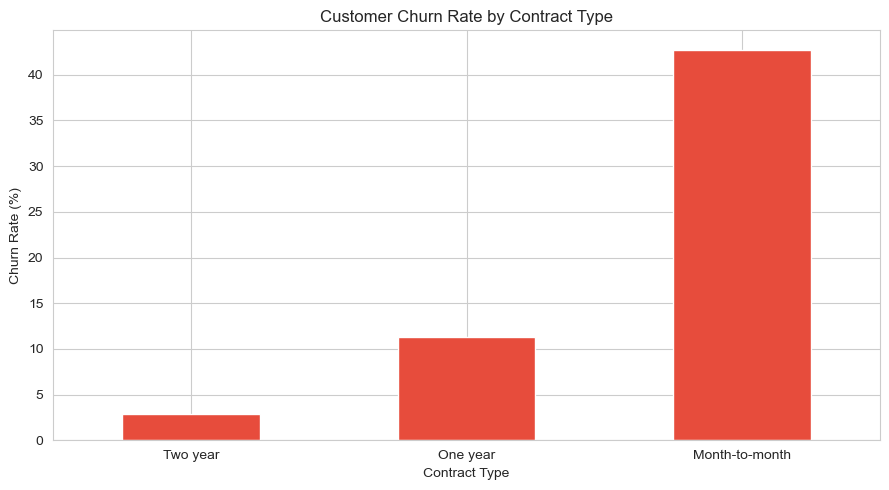

In [59]:

# STEP 11: Churn by Contract Type

contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print("CHURN RATE BY CONTRACT TYPE")
display(contract_churn.round(2))

# Visualize contract-wise churn rate

contract_churn["Yes"].sort_values().plot(
    kind="bar",
    figsize=(9, 5),
    color="#E74C3C"
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "../dashboard/churn_by_contract.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [60]:

# STEP 12: Create Dashboard Folder

import os

os.makedirs("../dashboard", exist_ok=True)

print("Dashboard folder is ready!")


Dashboard folder is ready!


Tenure Analysis by Churn Status:


,mean,median,min,max
Churn,,,,
No,37.57,38.0,0,72
Yes,17.98,10.0,1,72


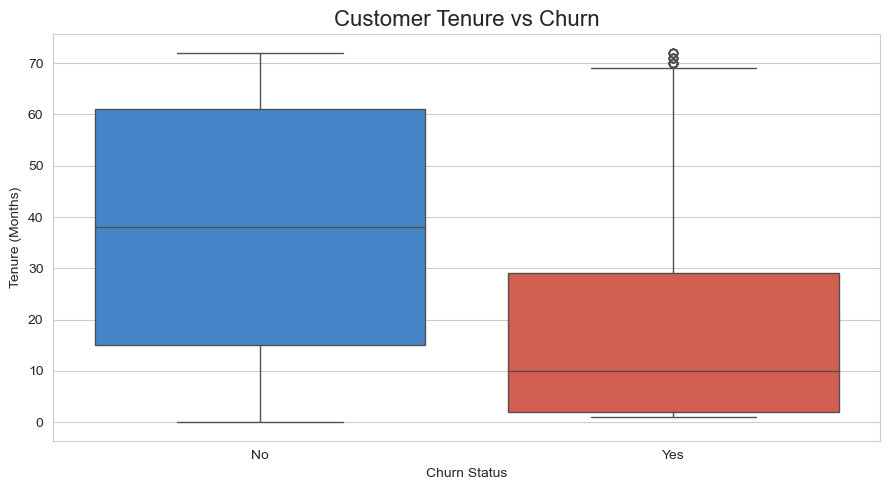

In [61]:
# STEP 13: Tenure vs Customer Churn

tenure_churn = df.groupby("Churn")["tenure"].agg(
    ["mean", "median", "min", "max"]
)

print("Tenure Analysis by Churn Status:")
display(tenure_churn.round(2))

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure",
    hue="Churn",
    palette={"No": "#2E86DE", "Yes": "#E74C3C"},
    legend=False
)

plt.title("Customer Tenure vs Churn", fontsize=16)
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")
plt.tight_layout()

plt.savefig("../dashboard/tenure_vs_churn.png",
            dpi=300, bbox_inches="tight")
plt.show()

Monthly Charges Analysis by Churn:


,mean,median
Churn,,
No,61.27,64.43
Yes,74.44,79.65


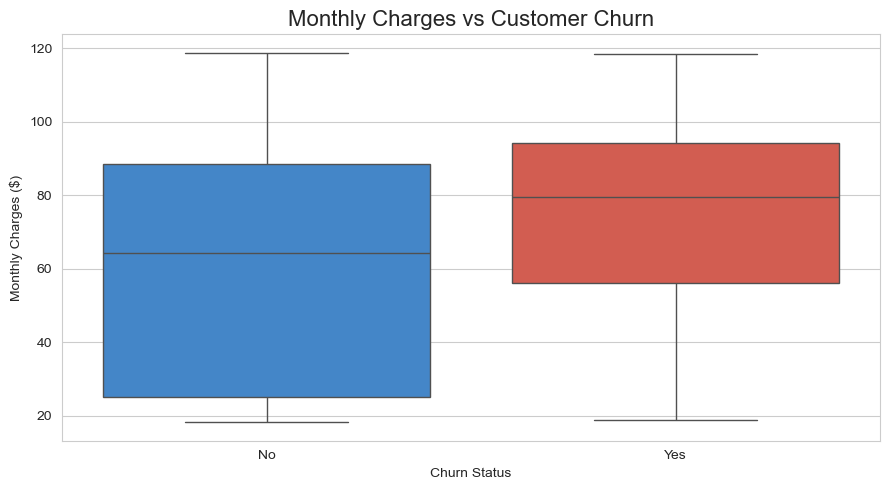

In [62]:
# STEP 14: Monthly Charges vs Churn

charges_churn = df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median"]
)

print("Monthly Charges Analysis by Churn:")
display(charges_churn.round(2))

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette={"No": "#2E86DE", "Yes": "#E74C3C"},
    legend=False
)

plt.title("Monthly Charges vs Customer Churn", fontsize=16)
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges ($)")
plt.tight_layout()

plt.savefig("../dashboard/monthly_charges_vs_churn.png",
            dpi=300, bbox_inches="tight")
plt.show()

Churn Rate by Payment Method:


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


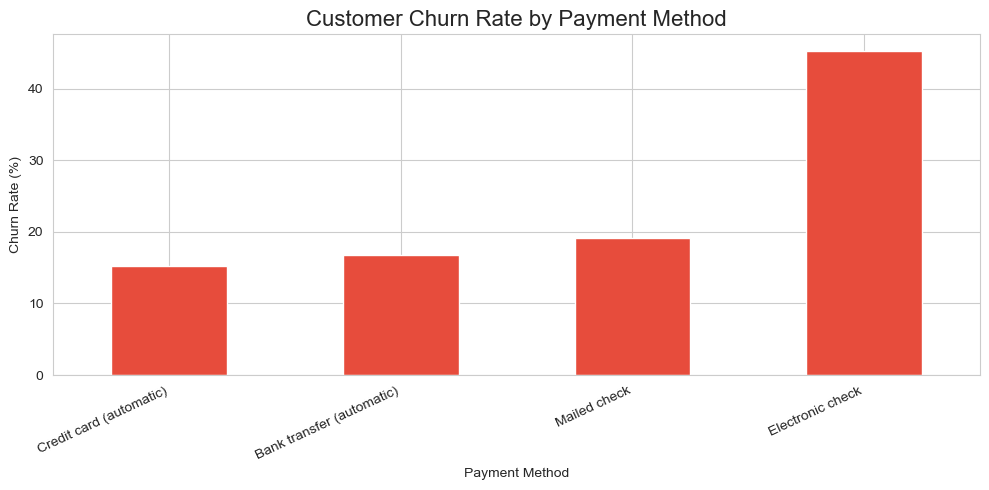

In [63]:
# STEP 15: Payment Method vs Churn

payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Rate by Payment Method:")
display(payment_churn.round(2))

payment_churn["Yes"].sort_values().plot(
    kind="bar",
    figsize=(10, 5),
    color="#E74C3C"
)

plt.title("Customer Churn Rate by Payment Method", fontsize=16)
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig("../dashboard/churn_by_payment_method.png",
            dpi=300, bbox_inches="tight")
plt.show()

Churn Rate by Internet Service:


Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


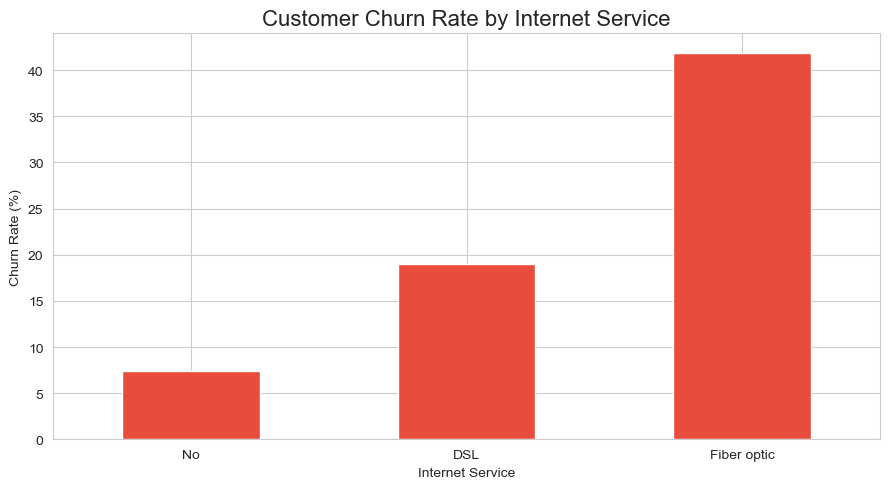

In [64]:
# STEP 16: Internet Service vs Churn

internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Rate by Internet Service:")
display(internet_churn.round(2))

internet_churn["Yes"].sort_values().plot(
    kind="bar",
    figsize=(9, 5),
    color="#E74C3C"
)

plt.title("Customer Churn Rate by Internet Service", fontsize=16)
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../dashboard/churn_by_internet_service.png",
            dpi=300, bbox_inches="tight")
plt.show()

Churn Rate by Senior Citizen Status:


Churn,No,Yes
SeniorCitizenLabel,,
Non-Senior Citizen,76.39,23.61
Senior Citizen,58.32,41.68


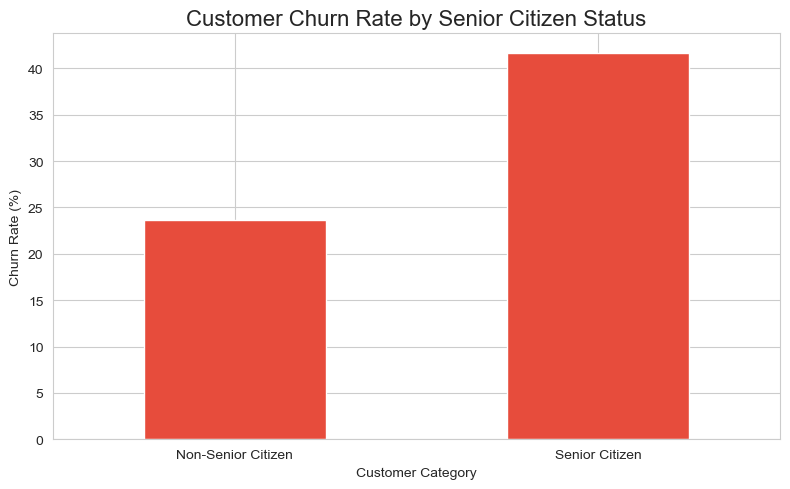

In [65]:
# STEP 17: Senior Citizen vs Churn

df["SeniorCitizenLabel"] = df["SeniorCitizen"].map({
    0: "Non-Senior Citizen",
    1: "Senior Citizen"
})

senior_churn = pd.crosstab(
    df["SeniorCitizenLabel"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Rate by Senior Citizen Status:")
display(senior_churn.round(2))

senior_churn["Yes"].plot(
    kind="bar",
    figsize=(8, 5),
    color="#E74C3C"
)

plt.title("Customer Churn Rate by Senior Citizen Status", fontsize=16)
plt.xlabel("Customer Category")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../dashboard/churn_by_senior_citizen.png",
            dpi=300, bbox_inches="tight")
plt.show()

Churn Rate by Partner Status:


Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66


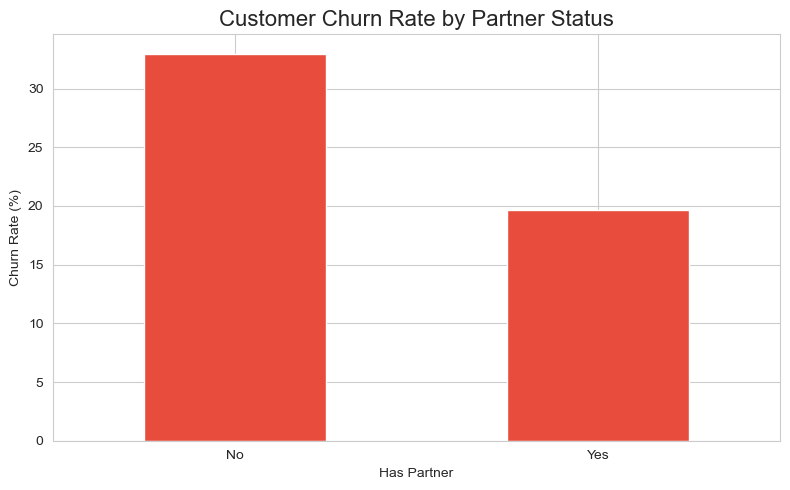

In [66]:
# STEP 18: Partner Status vs Churn

partner_churn = pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Rate by Partner Status:")
display(partner_churn.round(2))

partner_churn["Yes"].plot(
    kind="bar",
    figsize=(8, 5),
    color="#E74C3C"
)

plt.title("Customer Churn Rate by Partner Status", fontsize=16)
plt.xlabel("Has Partner")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../dashboard/churn_by_partner.png",
            dpi=300, bbox_inches="tight")
plt.show()

Churn Rate by Partner Status:


Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66


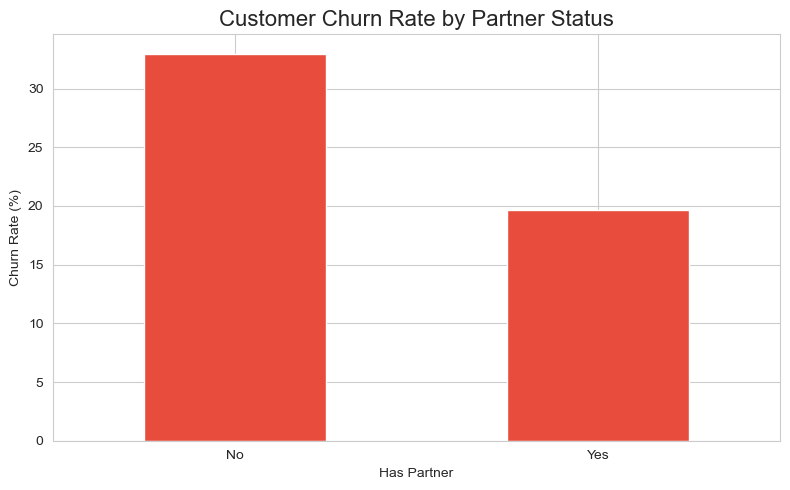

In [67]:
# STEP 18: Partner Status vs Churn

partner_churn = pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Rate by Partner Status:")
display(partner_churn.round(2))

partner_churn["Yes"].plot(
    kind="bar",
    figsize=(8, 5),
    color="#E74C3C"
)

plt.title("Customer Churn Rate by Partner Status", fontsize=16)
plt.xlabel("Has Partner")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../dashboard/churn_by_partner.png",
            dpi=300, bbox_inches="tight")
plt.show()

Churn Rate by Dependents:


Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.55,15.45


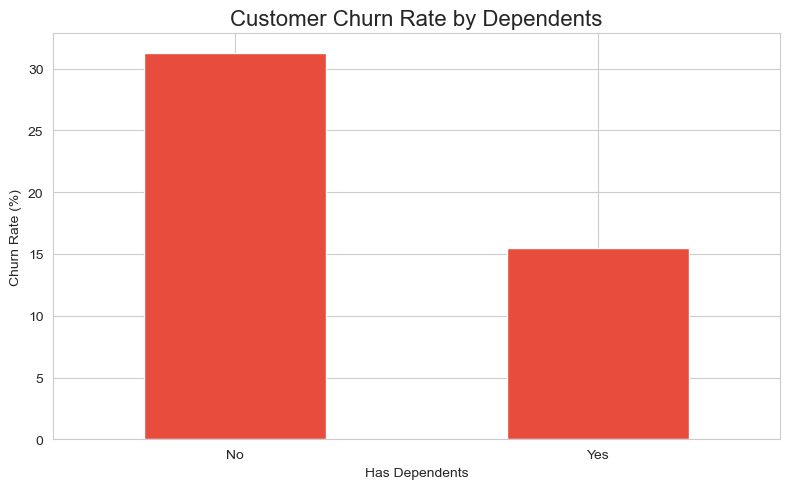

In [68]:
# STEP 19: Dependents vs Churn

dependents_churn = pd.crosstab(
    df["Dependents"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Rate by Dependents:")
display(dependents_churn.round(2))

dependents_churn["Yes"].plot(
    kind="bar",
    figsize=(8, 5),
    color="#E74C3C"
)

plt.title("Customer Churn Rate by Dependents", fontsize=16)
plt.xlabel("Has Dependents")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../dashboard/churn_by_dependents.png",
            dpi=300, bbox_inches="tight")
plt.show()

Churn Rate by Multiple Lines:


Churn,No,Yes
MultipleLines,,
No,74.96,25.04
No phone service,75.07,24.93
Yes,71.39,28.61


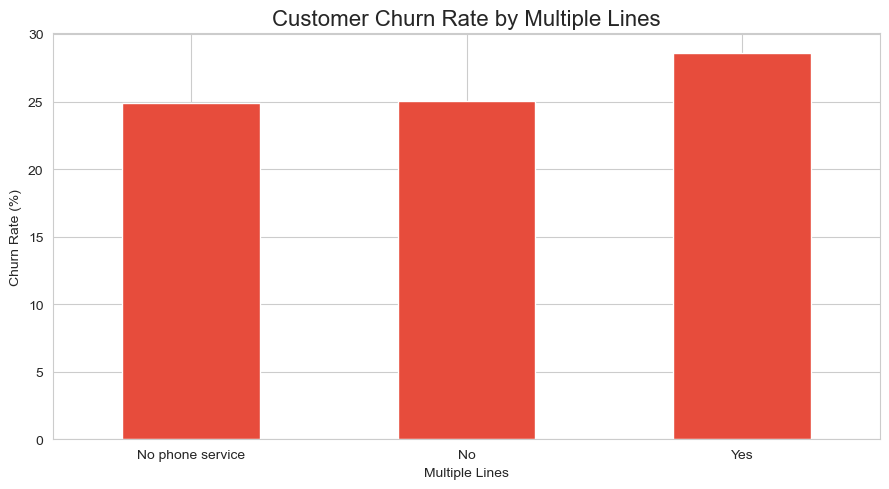

In [69]:
# STEP 20: Multiple Lines vs Churn

multiple_lines_churn = pd.crosstab(
    df["MultipleLines"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Rate by Multiple Lines:")
display(multiple_lines_churn.round(2))

multiple_lines_churn["Yes"].sort_values().plot(
    kind="bar",
    figsize=(9, 5),
    color="#E74C3C"
)

plt.title("Customer Churn Rate by Multiple Lines", fontsize=16)
plt.xlabel("Multiple Lines")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../dashboard/churn_by_multiple_lines.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [70]:
# STEP 21: Overall Churn Insights Summary

churn_summary = pd.DataFrame({
    "Analysis": [
        "Overall Churn Rate",
        "Month-to-Month Contract Churn",
        "One Year Contract Churn",
        "Two Year Contract Churn",
        "Electronic Check Churn",
        "Fiber Optic Churn",
        "Senior Citizen Churn",
        "Customers Without Partner Churn",
        "Customers Without Dependents Churn"
    ],
    "Churn Rate (%)": [
        churn_rate,
        contract_churn.loc["Month-to-month", "Yes"],
        contract_churn.loc["One year", "Yes"],
        contract_churn.loc["Two year", "Yes"],
        payment_churn.loc["Electronic check", "Yes"],
        internet_churn.loc["Fiber optic", "Yes"],
        senior_churn.loc["Senior Citizen", "Yes"],
        partner_churn.loc["No", "Yes"],
        dependents_churn.loc["No", "Yes"]
    ]
})

churn_summary["Churn Rate (%)"] = churn_summary["Churn Rate (%)"].round(2)

display(churn_summary)

churn_summary.to_csv(
    "../data/churn_insights_summary.csv",
    index=False
)

print("Churn insights summary saved successfully!")

,Analysis,Churn Rate (%)
0,Overall Churn Rate,26.54
1,Month-to-Month Contract Churn,42.71
2,One Year Contract Churn,11.27
3,Two Year Contract Churn,2.83
4,Electronic Check Churn,45.29
5,Fiber Optic Churn,41.89
6,Senior Citizen Churn,41.68
7,Customers Without Partner Churn,32.96
8,Customers Without Dependents Churn,31.28


Churn insights summary saved successfully!


In [71]:
# STEP 22: Customer Churn KPI Summary

total_customers = len(df)
churned_customers = (df["Churn"] == "Yes").sum()
retained_customers = (df["Churn"] == "No").sum()

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Customers",
        "Churned Customers",
        "Retained Customers",
        "Overall Churn Rate (%)",
        "Average Monthly Charges ($)",
        "Average Tenure (Months)"
    ],
    "Value": [
        total_customers,
        churned_customers,
        retained_customers,
        round(churn_rate, 2),
        round(df["MonthlyCharges"].mean(), 2),
        round(df["tenure"].mean(), 2)
    ]
})

display(kpi_summary)

kpi_summary.to_csv(
    "../data/customer_churn_kpis.csv",
    index=False
)

print("Customer churn KPI summary saved successfully!")

,KPI,Value
0,Total Customers,7043.00
1,Churned Customers,1869.00
2,Retained Customers,5174.00
3,Overall Churn Rate (%),26.54
4,Average Monthly Charges ($),64.76
5,Average Tenure (Months),32.37


Customer churn KPI summary saved successfully!


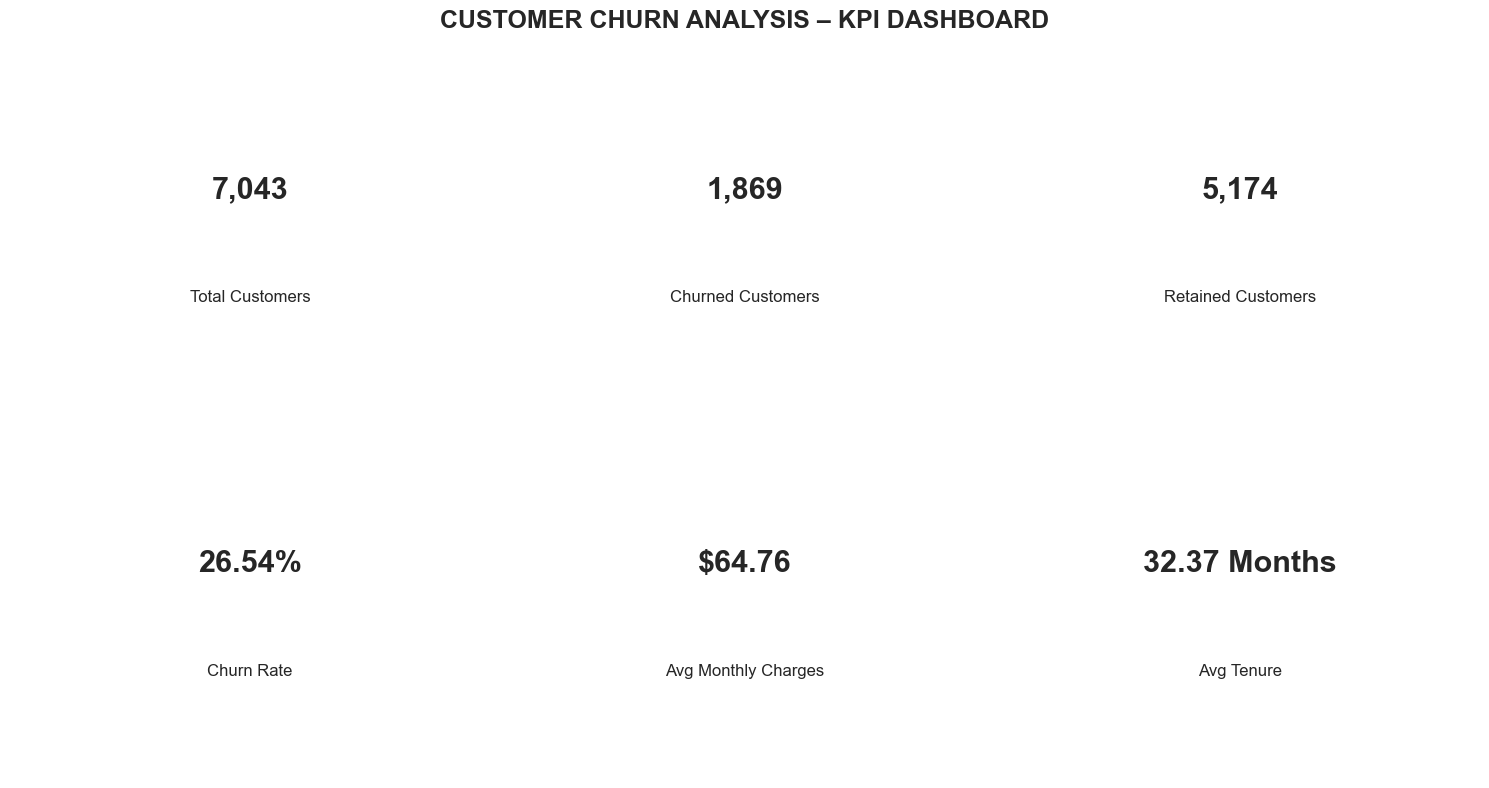

KPI Dashboard created successfully!


In [72]:
# STEP 23: Customer Churn KPI Dashboard

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

kpi_labels = [
    "Total Customers",
    "Churned Customers",
    "Retained Customers",
    "Churn Rate",
    "Avg Monthly Charges",
    "Avg Tenure"
]

kpi_values = [
    f"{total_customers:,}",
    f"{churned_customers:,}",
    f"{retained_customers:,}",
    f"{churn_rate:.2f}%",
    f"${df['MonthlyCharges'].mean():.2f}",
    f"{df['tenure'].mean():.2f} Months"
]

for ax, label, value in zip(axes, kpi_labels, kpi_values):
    ax.text(0.5, 0.6, value,
            ha="center", va="center",
            fontsize=22, fontweight="bold")
    ax.text(0.5, 0.3, label,
            ha="center", va="center", fontsize=12)
    ax.set_axis_off()

fig.suptitle(
    "CUSTOMER CHURN ANALYSIS – KPI DASHBOARD",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "../dashboard/customer_churn_kpi_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("KPI Dashboard created successfully!")

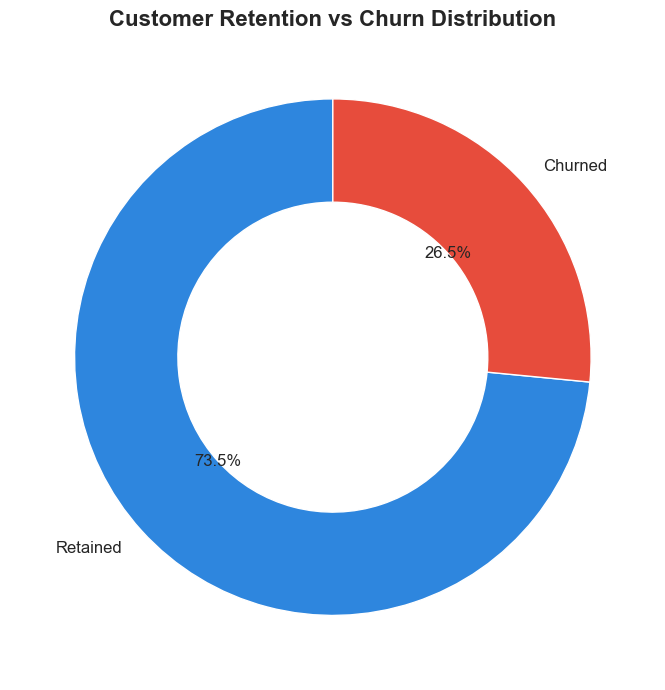

Churn donut chart saved successfully!


In [73]:
# STEP 24: Churn Distribution Donut Chart

churn_data = df["Churn"].value_counts()

plt.figure(figsize=(8, 7))

plt.pie(
    churn_data,
    labels=["Retained", "Churned"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#2E86DE", "#E74C3C"],
    wedgeprops={"width": 0.4, "edgecolor": "white"},
    textprops={"fontsize": 12}
)

plt.title(
    "Customer Retention vs Churn Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "../dashboard/customer_churn_donut.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Churn donut chart saved successfully!")

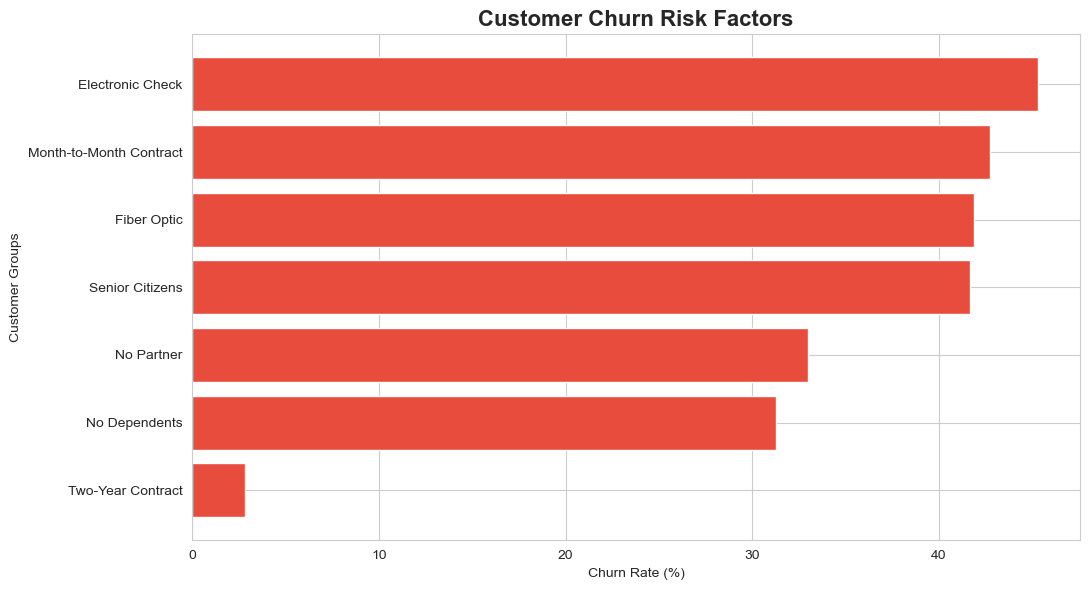

Churn risk factors chart saved successfully!


In [74]:
# STEP 25: Churn Risk Factors Comparison

risk_factors = pd.DataFrame({
    "Customer Group": [
        "Electronic Check",
        "Month-to-Month Contract",
        "Fiber Optic",
        "Senior Citizens",
        "No Partner",
        "No Dependents",
        "Two-Year Contract"
    ],
    "Churn Rate": [
        payment_churn.loc["Electronic check", "Yes"],
        contract_churn.loc["Month-to-month", "Yes"],
        internet_churn.loc["Fiber optic", "Yes"],
        senior_churn.loc["Senior Citizen", "Yes"],
        partner_churn.loc["No", "Yes"],
        dependents_churn.loc["No", "Yes"],
        contract_churn.loc["Two year", "Yes"]
    ]
})

risk_factors = risk_factors.sort_values(
    "Churn Rate", ascending=True
)

plt.figure(figsize=(11, 6))

plt.barh(
    risk_factors["Customer Group"],
    risk_factors["Churn Rate"],
    color="#E74C3C"
)

plt.title("Customer Churn Risk Factors",
          fontsize=16, fontweight="bold")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Customer Groups")
plt.tight_layout()

plt.savefig(
    "../dashboard/churn_risk_factors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Churn risk factors chart saved successfully!")

In [75]:
# STEP 26: Interactive Customer Churn Dashboard

from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Churn Rate by Contract Type",
        "Churn Rate by Payment Method",
        "Churn Rate by Internet Service",
        "Customer Tenure vs Churn"
    ),
    specs=[
        [{"type": "bar"}, {"type": "bar"}],
        [{"type": "bar"}, {"type": "box"}]
    ],
    vertical_spacing=0.15,
    horizontal_spacing=0.12
)

# 1. Contract Churn
fig.add_trace(
    go.Bar(
        x=contract_churn.index,
        y=contract_churn["Yes"],
        name="Contract Churn",
        marker_color="#E74C3C"
    ),
    row=1, col=1
)

# 2. Payment Method Churn
fig.add_trace(
    go.Bar(
        x=payment_churn.index,
        y=payment_churn["Yes"],
        name="Payment Churn",
        marker_color="#3498DB"
    ),
    row=1, col=2
)

# 3. Internet Service Churn
fig.add_trace(
    go.Bar(
        x=internet_churn.index,
        y=internet_churn["Yes"],
        name="Internet Churn",
        marker_color="#F39C12"
    ),
    row=2, col=1
)

# 4. Tenure vs Churn
for status, color in [
    ("No", "#3498DB"),
    ("Yes", "#E74C3C")
]:
    fig.add_trace(
        go.Box(
            y=df.loc[df["Churn"] == status, "tenure"],
            name=status,
            marker_color=color,
            boxmean=True
        ),
        row=2, col=2
    )

fig.update_layout(
    title={
        "text": "CUSTOMER CHURN ANALYSIS – INTERACTIVE DASHBOARD",
        "x": 0.5
    },
    height=850,
    template="plotly_white",
    showlegend=False
)

fig.update_yaxes(title_text="Churn Rate (%)", row=1, col=1)
fig.update_yaxes(title_text="Churn Rate (%)", row=1, col=2)
fig.update_yaxes(title_text="Churn Rate (%)", row=2, col=1)
fig.update_yaxes(title_text="Tenure (Months)", row=2, col=2)

dashboard_path = (
    "../dashboard/Customer_Churn_Interactive_Dashboard.html"
)

fig.write_html(
    dashboard_path,
    include_plotlyjs=True,
    full_html=True
)

fig.show()

print("Interactive dashboard created successfully!")
print("Dashboard Path:", dashboard_path)


Interactive dashboard created successfully!
Dashboard Path: ../dashboard/Customer_Churn_Interactive_Dashboard.html


In [76]:
# STEP 26: Interactive Customer Churn Dashboard

from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Churn Rate by Contract Type",
        "Churn Rate by Payment Method",
        "Churn Rate by Internet Service",
        "Customer Tenure vs Churn"
    ),
    specs=[
        [{"type": "bar"}, {"type": "bar"}],
        [{"type": "bar"}, {"type": "box"}]
    ],
    vertical_spacing=0.15,
    horizontal_spacing=0.12
)

# 1. Contract Churn
fig.add_trace(
    go.Bar(
        x=contract_churn.index,
        y=contract_churn["Yes"],
        name="Contract Churn",
        marker_color="#E74C3C"
    ),
    row=1, col=1
)

# 2. Payment Method Churn
fig.add_trace(
    go.Bar(
        x=payment_churn.index,
        y=payment_churn["Yes"],
        name="Payment Churn",
        marker_color="#3498DB"
    ),
    row=1, col=2
)

# 3. Internet Service Churn
fig.add_trace(
    go.Bar(
        x=internet_churn.index,
        y=internet_churn["Yes"],
        name="Internet Churn",
        marker_color="#F39C12"
    ),
    row=2, col=1
)

# 4. Tenure vs Churn
for status, color in [
    ("No", "#3498DB"),
    ("Yes", "#E74C3C")
]:
    fig.add_trace(
        go.Box(
            y=df.loc[df["Churn"] == status, "tenure"],
            name=status,
            marker_color=color,
            boxmean=True
        ),
        row=2, col=2
    )

fig.update_layout(
    title={
        "text": "CUSTOMER CHURN ANALYSIS – INTERACTIVE DASHBOARD",
        "x": 0.5
    },
    height=850,
    template="plotly_white",
    showlegend=False
)

fig.update_yaxes(title_text="Churn Rate (%)", row=1, col=1)
fig.update_yaxes(title_text="Churn Rate (%)", row=1, col=2)
fig.update_yaxes(title_text="Churn Rate (%)", row=2, col=1)
fig.update_yaxes(title_text="Tenure (Months)", row=2, col=2)

dashboard_path = (
    "../dashboard/Customer_Churn_Interactive_Dashboard.html"
)

fig.write_html(
    dashboard_path,
    include_plotlyjs=True,
    full_html=True
)

fig.show()

print("Interactive dashboard created successfully!")
print("Dashboard Path:", dashboard_path)

Interactive dashboard created successfully!
Dashboard Path: ../dashboard/Customer_Churn_Interactive_Dashboard.html


In [77]:
# STEP 27: Export Dashboard Preview

import os

preview_folder = "../dashboard"
os.makedirs(preview_folder, exist_ok=True)

print("Dashboard folder:", os.path.abspath(preview_folder))
print("HTML dashboard exists:",
      os.path.exists(
          "../dashboard/Customer_Churn_Interactive_Dashboard.html"
      ))

Dashboard folder: C:\Users\gowth\OneDrive\Documents\FUTURE_DS_02\dashboard
HTML dashboard exists: True


In [78]:
%pip install -U kaleido

Defaulting to user installation because normal site-packages is not writeable
  Using cached kaleido-1.5.0-py3-none-any.whl.metadata (7.5 kB)
Using cached kaleido-1.5.0-py3-none-any.whl (55 kB)
  Attempting uninstall: kaleido
    Found existing installation: kaleido 1.1.0
    Uninstalling kaleido-1.1.0:
      Successfully uninstalled kaleido-1.1.0
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [79]:
# STEP 27.1: Export Dashboard Preview

fig.write_image(
    "../dashboard/Customer_Churn_Dashboard_Preview.png",
    width=1400,
    height=1000,
    scale=2
)

print("Dashboard preview saved successfully!")

ValueError: 
Image export using the "kaleido" engine requires the kaleido package,
which can be installed using pip:
    $ pip install -U kaleido


In [ ]:
%pip install --upgrade kaleido

In [ ]:
import kaleido
import plotly.io as pio

print("Kaleido version:", kaleido.__version__)
print("Kaleido installed successfully!")

In [ ]:
import sys

print("Python Executable:", sys.executable)
print("Python Version:", sys.version)

In [ ]:
import sys
!{sys.executable} -m pip install -U kaleido

In [ ]:
import kaleido

print("Kaleido Version:", kaleido.__version__)
print("Installation Successful!")

In [ ]:
import sys
import site

user_site = site.getusersitepackages()

if user_site not in sys.path:
    sys.path.insert(0, user_site)

import kaleido

print("Kaleido Version:", kaleido.__version__)
print("Kaleido loaded successfully!")

In [ ]:
import kaleido
import plotly.io as pio

print("Kaleido imported successfully!")
print("Plotly version:", __import__("plotly").__version__)
print("Kaleido module:", kaleido.__file__)

In [ ]:
import shutil

print("Chrome path:", shutil.which("chrome"))
print("Chrome path:", shutil.which("google-chrome"))

In [82]:
import sys
import site

user_site = site.getusersitepackages()

if user_site not in sys.path:
    sys.path.insert(0, user_site)

from kaleido import get_chrome

get_chrome()

<coroutine object get_chrome at 0x00000271639FE7A0>

In [83]:
import plotly.io as pio

pio.write_image(
    fig,
    "../dashboard/Customer_Churn_Dashboard_Preview.png",
    width=1400,
    height=1000,
    scale=2
)

print("Dashboard preview saved successfully!")

ValueError: 
Image export using the "kaleido" engine requires the kaleido package,
which can be installed using pip:
    $ pip install -U kaleido


In [84]:
import os
from pathlib import Path

dashboard_path = Path(
    "../dashboard/Customer_Churn_Interactive_Dashboard.html"
).resolve()

print("Dashboard exists:", dashboard_path.exists())
print("Dashboard location:", dashboard_path)

Dashboard exists: True
Dashboard location: C:\Users\gowth\OneDrive\Documents\FUTURE_DS_02\dashboard\Customer_Churn_Interactive_Dashboard.html


In [85]:
from pathlib import Path

readme_content = """
# Customer Retention & Churn Analysis

## Project Overview
This project analyzes customer churn in a telecommunications
company using the Telco Customer Churn dataset.

The goal is to identify customer churn patterns, understand
the factors associated with churn, and suggest retention strategies.

## Dataset
- Source: Kaggle – Telco Customer Churn
- Total Customers: 7,043
- Total Columns: 21

## Tools & Technologies
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Plotly
- Jupyter Notebook

## Key Performance Indicators
- Total Customers: 7,043
- Churned Customers: 1,869
- Retained Customers: 5,174
- Overall Churn Rate: 26.54%
- Average Monthly Charges: $64.76
- Average Customer Tenure: 32.37 months

## Key Findings
1. Month-to-month contract customers have a 42.71% churn rate.
2. Electronic check users have a 45.29% churn rate.
3. Fiber optic customers have a 41.89% churn rate.
4. Senior citizens have a 41.68% churn rate.
5. Customers with shorter tenure are more likely to churn.

## Dashboard
Interactive dashboard:
`dashboard/Customer_Churn_Interactive_Dashboard.html`

## Project Structure
- data/ – Original and cleaned datasets
- notebooks/ – Jupyter Notebook analysis
- dashboard/ – Charts and interactive dashboard
- reports/ – Final project reports

## Conclusion
The analysis identifies customer groups with higher churn
rates. Targeted retention offers, improved onboarding,
pricing reviews, and customer support may help improve retention.
"""

readme_path = Path("../README.md")
readme_path.write_text(readme_content, encoding="utf-8")

print("README created successfully!")
print("Location:", readme_path.resolve())
print("Exists:", readme_path.exists())

PermissionError: [Errno 13] Permission denied: '..\\README.md'

In [86]:
from pathlib import Path
import os

project_folder = Path.cwd().parent
print("Project folder:", project_folder)
print("Folder exists:", project_folder.exists())
print("Folder writable:", os.access(project_folder, os.W_OK))

Project folder: C:\Users\gowth\OneDrive\Documents\FUTURE_DS_02
Folder exists: True
Folder writable: True


In [87]:
from pathlib import Path

project_folder = Path.cwd().parent
readme_path = project_folder / "README.md"

content = """# Customer Retention & Churn Analysis

## Project Overview
This project analyzes customer churn patterns in a telecommunications company.

## Dataset
- Dataset: Telco Customer Churn
- Total Customers: 7,043
- Total Columns: 21

## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Plotly
- Jupyter Notebook

## Key Performance Indicators
- Total Customers: 7,043
- Churned Customers: 1,869
- Retained Customers: 5,174
- Churn Rate: 26.54%
- Average Monthly Charges: $64.76
- Average Tenure: 32.37 months

## Key Findings
- Month-to-month contract churn: 42.71%
- Electronic check churn: 45.29%
- Fiber optic churn: 41.89%
- Senior citizen churn: 41.68%

## Interactive Dashboard
dashboard/Customer_Churn_Interactive_Dashboard.html

## Conclusion
The analysis identifies customer groups with higher churn rates
and highlights opportunities for improving customer retention.
"""

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(content)

print("README created successfully!")
print("File:", readme_path)
print("Exists:", readme_path.exists())

PermissionError: [Errno 13] Permission denied: 'C:\\Users\\gowth\\OneDrive\\Documents\\FUTURE_DS_02\\README.md'

In [88]:
from pathlib import Path

project_folder = Path.cwd().parent
readme_path = project_folder / "README.md"

print("Exists:", readme_path.exists())
print("Is file:", readme_path.is_file())
print("Is folder:", readme_path.is_dir())
print("Project folder:", project_folder)

Exists: True
Is file: False
Is folder: True
Project folder: C:\Users\gowth\OneDrive\Documents\FUTURE_DS_02


In [89]:
from pathlib import Path

project_folder = Path.cwd().parent
readme_path = project_folder / "README_Project.md"

content = """# Customer Retention & Churn Analysis

## Project Overview
Analysis of customer churn patterns in a telecommunications company.

## Dataset
- Telco Customer Churn
- Total Customers: 7,043
- Total Columns: 21

## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Plotly
- Jupyter Notebook

## Key Performance Indicators
- Total Customers: 7,043
- Churned Customers: 1,869
- Retained Customers: 5,174
- Churn Rate: 26.54%
- Average Monthly Charges: $64.76
- Average Tenure: 32.37 months

## Key Findings
- Month-to-month contract churn: 42.71%
- Electronic check churn: 45.29%
- Fiber optic churn: 41.89%
- Senior citizen churn: 41.68%

## Dashboard
dashboard/Customer_Churn_Interactive_Dashboard.html

## Conclusion
The analysis identifies customer groups with higher churn rates
and provides insights for improving customer retention.
"""

readme_path.write_text(content, encoding="utf-8")

print("README created:", readme_path.exists())
print("Saved at:", readme_path)

README created: True
Saved at: C:\Users\gowth\OneDrive\Documents\FUTURE_DS_02\README_Project.md


In [90]:
from pathlib import Path

project_folder = Path.cwd().parent
readme_path = project_folder / "README_Project.md"

content = """# Customer Retention & Churn Analysis

## Project Overview
Analysis of customer churn patterns in a telecommunications company.

## Dataset
- Telco Customer Churn
- Total Customers: 7,043
- Total Columns: 21

## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Plotly
- Jupyter Notebook

## Key Performance Indicators
- Total Customers: 7,043
- Churned Customers: 1,869
- Retained Customers: 5,174
- Churn Rate: 26.54%
- Average Monthly Charges: $64.76
- Average Tenure: 32.37 months

## Key Findings
- Month-to-month contract churn: 42.71%
- Electronic check churn: 45.29%
- Fiber optic churn: 41.89%
- Senior citizen churn: 41.68%

## Dashboard
dashboard/Customer_Churn_Interactive_Dashboard.html

## Conclusion
The analysis identifies customer groups with higher churn rates
and provides insights for improving customer retention.
"""

readme_path.write_text(content, encoding="utf-8")

print("README created:", readme_path.exists())
print("Saved at:", readme_path)

README created: True
Saved at: C:\Users\gowth\OneDrive\Documents\FUTURE_DS_02\README_Project.md


In [91]:
try:
    import reportlab
    print("ReportLab is installed!")
    print("Version:", reportlab.Version)
except ImportError:
    print("ReportLab is not installed.")

ReportLab is not installed.


In [99]:
import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "reportlab"
])

print("ReportLab installation completed!")

ReportLab installation completed!


In [100]:
from pathlib import Path
from datetime import datetime

from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Table, TableStyle, Image, PageBreak
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from reportlab.lib.pagesizes import A4

# Project paths
project_folder = Path.cwd().parent
dashboard_folder = project_folder / "dashboard"
reports_folder = project_folder / "reports"

reports_folder.mkdir(exist_ok=True)

pdf_path = reports_folder / "Customer_Churn_Analysis_Report.pdf"

# PDF document
doc = SimpleDocTemplate(
    str(pdf_path),
    pagesize=A4,
    rightMargin=45,
    leftMargin=45,
    topMargin=45,
    bottomMargin=45
)

styles = getSampleStyleSheet()

title_style = ParagraphStyle(
    "ReportTitle",
    parent=styles["Title"],
    fontSize=21,
    textColor=colors.HexColor("#17365D"),
    alignment=TA_CENTER,
    spaceAfter=15
)

heading_style = ParagraphStyle(
    "SectionHeading",
    parent=styles["Heading2"],
    textColor=colors.HexColor("#17365D"),
    spaceBefore=14,
    spaceAfter=8
)

body_style = styles["BodyText"]

story = []

# Title and project details
story.append(Paragraph(
    "CUSTOMER RETENTION &amp; CHURN ANALYSIS",
    title_style
))

story.append(Paragraph(
    "Final Data Analytics Project Report",
    ParagraphStyle(
        "Subtitle",
        parent=styles["Normal"],
        alignment=TA_CENTER,
        fontSize=12
    )
))

story.append(Spacer(1, 15))

story.append(Paragraph(
    f"Report Date: {datetime.now().strftime('%d-%m-%Y')}",
    body_style
))

story.append(Paragraph(
    f"Project Folder: {project_folder}",
    body_style
))

# Overview
story.append(Paragraph("1. Project Overview", heading_style))

story.append(Paragraph(
    "This project analyzes customer churn patterns in a "
    "telecommunications company using the Telco Customer Churn "
    "dataset. The objective is to understand customer retention, "
    "identify groups with higher churn rates, and suggest "
    "strategies to improve customer loyalty.",
    body_style
))

# Dataset
story.append(Paragraph("2. Dataset Details", heading_style))

dataset_data = [
    ["Metric", "Value"],
    ["Total Customers", "7,043"],
    ["Total Columns", "21"],
    ["Churned Customers", "1,869"],
    ["Retained Customers", "5,174"]
]

table = Table(dataset_data, colWidths=[220, 220])
table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 8),
]))
story.append(table)

# Tools
story.append(Paragraph("3. Tools and Technologies", heading_style))
story.append(Paragraph(
    "Python, Pandas, NumPy, Matplotlib, Seaborn, Plotly "
    "and Jupyter Notebook.",
    body_style
))

# KPIs
story.append(Paragraph("4. Key Performance Indicators", heading_style))

kpi_data = [
    ["KPI", "Result"],
    ["Total Customers", "7,043"],
    ["Churned Customers", "1,869"],
    ["Retained Customers", "5,174"],
    ["Overall Churn Rate", "26.54%"],
    ["Average Monthly Charges", "$64.76"],
    ["Average Tenure", "32.37 months"]
]

table = Table(kpi_data, colWidths=[220, 220])
table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
    ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 8),
]))
story.append(table)

# Findings
story.append(Paragraph("5. Key Findings", heading_style))

findings = [
    "Month-to-month contract customers have a 42.71% churn rate.",
    "Electronic check users have the highest payment-method churn rate at 45.29%.",
    "Fiber optic customers have a churn rate of 41.89%.",
    "Senior citizens have a churn rate of 41.68%.",
    "Customers who churned had a lower average tenure than retained customers.",
    "Customers who churned had higher average monthly charges."
]

for finding in findings:
    story.append(Paragraph("• " + finding, body_style))
    story.append(Spacer(1, 5))

# Recommendations
story.append(Paragraph("6. Recommendations", heading_style))

recommendations = [
    "Provide retention offers to month-to-month customers.",
    "Review pricing and service quality for fiber optic customers.",
    "Encourage convenient automatic payment methods.",
    "Improve onboarding and support during the first year.",
    "Offer personalized assistance to customers at higher churn risk."
]

for item in recommendations:
    story.append(Paragraph("• " + item, body_style))
    story.append(Spacer(1, 5))

# Charts
story.append(PageBreak())
story.append(Paragraph("7. Data Visualizations", heading_style))

chart_files = [
    "customer_churn_distribution.png",
    "churn_by_contract.png",
    "tenure_vs_churn.png",
    "monthly_charges_vs_churn.png",
    "churn_by_payment_method.png",
    "churn_by_internet_service.png",
    "churn_risk_factors.png"
]

for chart_name in chart_files:
    chart_path = dashboard_folder / chart_name

    if chart_path.exists():
        story.append(Paragraph(
            chart_name.replace(".png", "").replace("_", " ").title(),
            heading_style
        ))

        img = Image(str(chart_path))
        img._restrictSize(6.2 * inch, 3.8 * inch)
        story.append(img)
        story.append(Spacer(1, 12))

# Dashboard details
story.append(Paragraph("8. Interactive Dashboard", heading_style))

story.append(Paragraph(
    "Interactive dashboard file: "
    "dashboard/Customer_Churn_Interactive_Dashboard.html",
    body_style
))

# Conclusion
story.append(Paragraph("9. Conclusion", heading_style))

story.append(Paragraph(
    "The analysis identifies important customer groups associated "
    "with higher churn rates. Month-to-month contracts, electronic "
    "check payments, fiber optic service and shorter customer tenure "
    "are notable patterns. Targeted retention strategies and improved "
    "customer support may help reduce churn. These findings represent "
    "associations in the dataset and do not establish causation.",
    body_style
))

# Footer
def add_footer(canvas, document):
    canvas.saveState()
    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(colors.grey)
    canvas.drawString(45, 25, "Customer Retention & Churn Analysis")
    canvas.drawRightString(A4[0] - 45, 25, f"Page {document.page}")
    canvas.restoreState()

# Generate PDF
doc.build(
    story,
    onFirstPage=add_footer,
    onLaterPages=add_footer
)

print("=" * 50)
print("PDF REPORT GENERATED SUCCESSFULLY!")
print("File:", pdf_path.name)
print("Location:", pdf_path.resolve())
print("File exists:", pdf_path.exists())
print("=" * 50)

PDF REPORT GENERATED SUCCESSFULLY!
File: Customer_Churn_Analysis_Report.pdf
Location: C:\Users\gowth\OneDrive\Documents\FUTURE_DS_02\reports\Customer_Churn_Analysis_Report.pdf
File exists: True
